## Yahoo Finace Libaray

In [2]:
!pip install -q yfinance

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Define the stock symbol and date range
stock_symbol = "AAME"
start_date = "2013-01-01"
end_date = "2023-01-01"

# Fetch historical stock data from Yahoo Finance
stock_data = yf.download(stock_symbol, start=start_date, end=end_date)

# Reset index to make 'Date' a column again
stock_data.reset_index(inplace=True)

/tmp/ipykernel_1461/2153819629.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(stock_symbol, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


## Plot historical data

In [4]:
import time
from datetime import datetime
import plotly.express as px
import pandas as pd

# Fix yfinance MultiIndex columns
if isinstance(stock_data.columns, pd.MultiIndex):
    stock_data.columns = stock_data.columns.get_level_values(0)

# Make sure Date is a column
if "Date" not in stock_data.columns:
    stock_data = stock_data.reset_index()

def plot_stock_data(data, title):
    '''Function for plotting stock data'''
    plot = px.line(
        data,
        x="Date",
        y="Close",
        hover_name="Date",
        line_shape="linear",
        title=title
    )
    return plot

plot_stock_data(stock_data[-30:], "AAME Stock Prices")


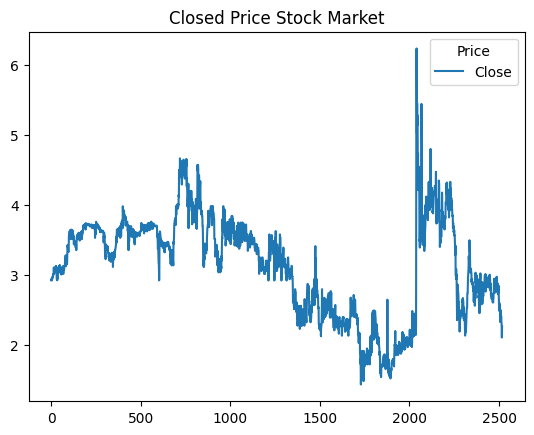

In [5]:
stock_data[['Close']].plot()
plt.title("Closed Price Stock Market")
plt.show()

## Outlier checking

In [6]:
# Create df from the existing stock dataset
df = stock_data.copy()

# Convert the Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Display the dataset
df


Price,Date,Close,High,Low,Open,Volume
0,2013-01-02,2.922021,2.958547,2.821577,2.821577,3500
1,2013-01-03,2.922021,3.031597,2.821577,2.912890,5500
2,2013-01-04,2.922021,2.967678,2.876365,2.876365,3000
3,2013-01-07,2.949415,2.949415,2.785052,2.922022,4700
4,2013-01-08,2.922021,2.940284,2.894627,2.922021,3800
...,...,...,...,...,...,...
2513,2022-12-23,2.335903,2.335903,2.326251,2.326251,1900
2514,2022-12-27,2.316598,2.335903,2.268336,2.268336,5900
2515,2022-12-28,2.249031,2.287641,2.249031,2.287641,1400
2516,2022-12-29,2.104243,2.268335,2.104243,2.258683,9100


In [7]:
# Specify the column to analyze for outliers
column_name = 'Open'

# Calculate the IQR (Interquartile Range)
Q1 = df[column_name].quantile(0.25)
Q3 = df[column_name].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify and count outliers
outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
num_outliers = len(outliers)

# Display the number of outliers
print(f'Number of outliers in {column_name}: {num_outliers}')


Number of outliers in Open: 3


In [8]:
# Specify the column to analyze for outliers
column_name = 'Close'

# Calculate the IQR (Interquartile Range)
Q1 = df[column_name].quantile(0.25)
Q3 = df[column_name].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify and count outliers
outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
num_outliers = len(outliers)

# Display the number of outliers
print(f'Number of outliers in {column_name}: {num_outliers}')


Number of outliers in Close: 5


/usr/local/lib/python3.13/dist-packages/seaborn/_base.py:1608: UserWarning:

Vertical orientation ignored with only `x` specified.

/tmp/ipykernel_1461/2118448779.py:10: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




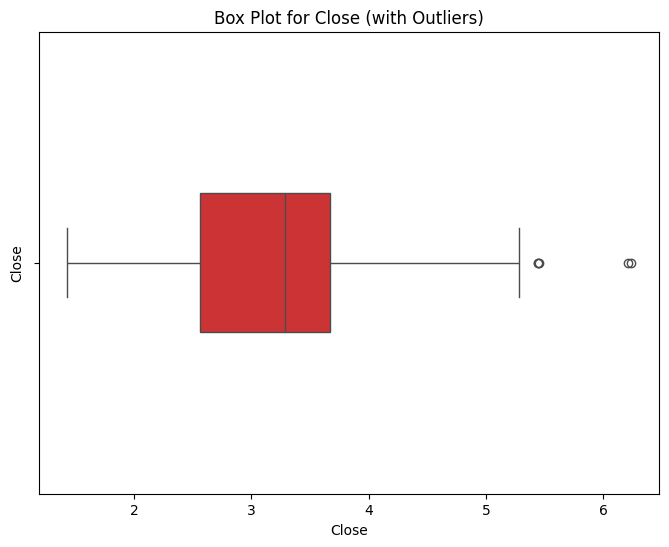

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns


# Specify the column to visualize outliers
column_name = 'Close'

# Create a box plot to visualize outliers
plt.figure(figsize=(8, 6))
sns.boxplot(x=df[column_name], orient='v', width=0.3, palette='Set1')
plt.title(f'Box Plot for {column_name} (with Outliers)')
plt.ylabel(column_name)
plt.show()


## Hyperparameters

In [10]:
import torch
import numpy as np
import pandas as pd
import yfinance as yf
from google.colab import files

torch.manual_seed(42)
np.random.seed(42)

# Download AAME once for all three models
stock_symbol = "AAME"
start_date = "2013-01-01"
end_date = "2023-01-01"

raw = yf.download(
    stock_symbol,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

if raw.empty:
    raise ValueError("AAME download failed")

if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)

raw = raw.rename(
    columns={"Adj Close": "Adjusted Close"}
)

columns_to_normalize = [
    "Low", "Open", "Volume",
    "High", "Close", "Adjusted Close"
]

raw = raw[columns_to_normalize].sort_index().copy()
raw.index.name = "Date"

if raw.isna().any().any():
    raise ValueError("Missing AAME stock values")

# Split chronologically: 70/15/15
train_size = int(len(raw) * 0.70)
test_size = int(len(raw) * 0.15)

train_raw = raw.iloc[:train_size].copy()
test_raw = raw.iloc[
    train_size:train_size + test_size
].copy()
val_raw = raw.iloc[
    train_size + test_size:
].copy()

# Export original stock data
train_raw.to_csv("AAME_Training.csv")
test_raw.to_csv("AAME_Testing.csv")
val_raw.to_csv("AAME_Validation.csv")

print("Training:", len(train_raw))
print("Testing:", len(test_raw))
print("Validation:", len(val_raw))

# Normalize using ONLY training data
train_tensor = torch.tensor(
    train_raw.to_numpy(),
    dtype=torch.float32
)

mean = train_tensor.mean(dim=0)
std = train_tensor.std(dim=0)
std = torch.where(
    std == 0,
    torch.ones_like(std),
    std
)

train_data = (
    train_raw - mean.numpy()
) / std.numpy()

test_data = (
    test_raw - mean.numpy()
) / std.numpy()

train_data = train_data.reset_index()
test_data = test_data.reset_index()

feature_columns = ["Low", "Open", "High"]
target_column = "Close"

# Prepare tensors shared by all three models
train_features = torch.tensor(
    train_data[feature_columns].to_numpy(),
    dtype=torch.float32
)

train_target = torch.tensor(
    train_data[target_column].to_numpy(),
    dtype=torch.float32
)

test_features = torch.tensor(
    test_data[feature_columns].to_numpy(),
    dtype=torch.float32
)

test_target = torch.tensor(
    test_data[target_column].to_numpy(),
    dtype=torch.float32
)

# Download datasets immediately
files.download("AAME_Training.csv")
files.download("AAME_Testing.csv")
files.download("AAME_Validation.csv")


Training: 1762
Testing: 377
Validation: 379


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## LSTM

LSTM Epoch 10/100 | Train: 0.96205 | Test: 4.41955
LSTM Epoch 20/100 | Train: 0.87910 | Test: 3.93786
LSTM Epoch 30/100 | Train: 0.73475 | Test: 3.15724
LSTM Epoch 40/100 | Train: 0.50420 | Test: 2.01215
LSTM Epoch 50/100 | Train: 0.22830 | Test: 0.79927
LSTM Epoch 60/100 | Train: 0.05967 | Test: 0.20489
LSTM Epoch 70/100 | Train: 0.04876 | Test: 0.14489
LSTM Epoch 80/100 | Train: 0.03578 | Test: 0.11647
LSTM Epoch 90/100 | Train: 0.02522 | Test: 0.14769
LSTM Epoch 100/100 | Train: 0.02372 | Test: 0.16255


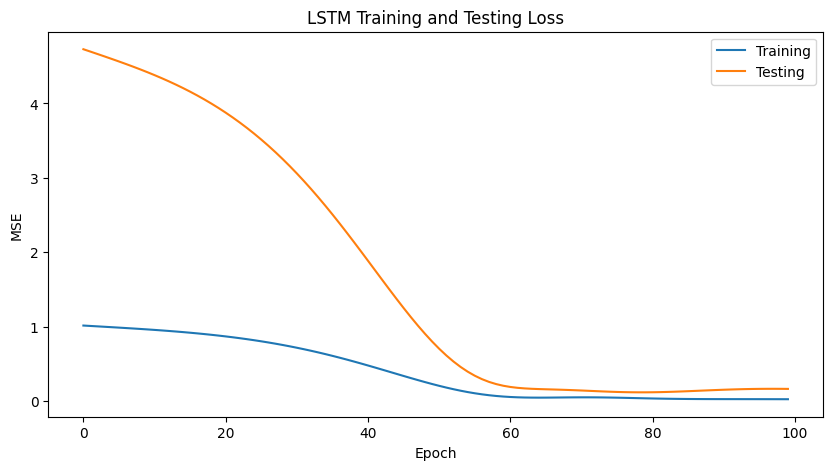

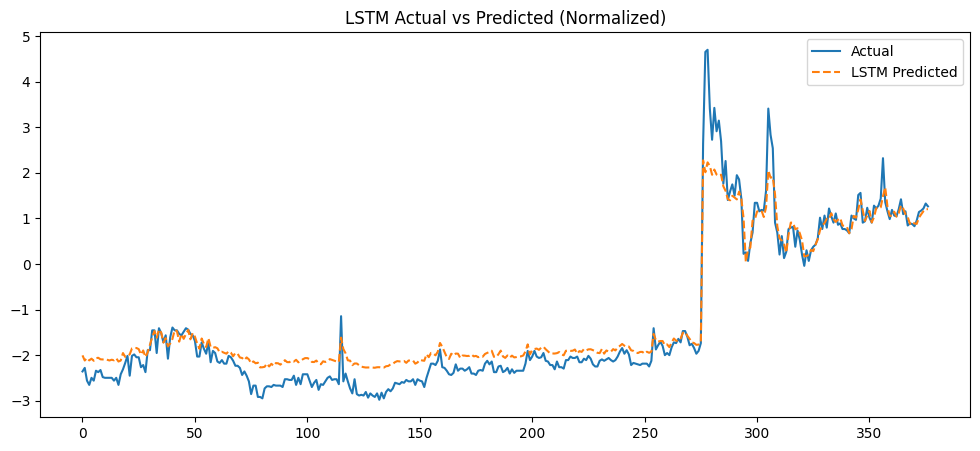

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

class LSTMModel(nn.Module):
    def __init__(
        self, input_size, hidden_size,
        output_size, num_layers
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True
        )

        self.fc_output = nn.Linear(
            hidden_size, output_size
        )

    def forward(self, x):
        _, (hn, _) = self.lstm(x)
        return self.fc_output(hn[-1, :, :])


model_lstm = LSTMModel(3, 64, 1, 2)

criterion_lstm = nn.MSELoss()
optimizer_lstm = optim.Adam(
    model_lstm.parameters(),
    lr=0.001
)

train_losses_lstm = []
test_losses_lstm = []

for epoch in range(100):
    model_lstm.train()
    optimizer_lstm.zero_grad()

    outputs_lstm = model_lstm(
        train_features.unsqueeze(1)
    )

    loss_lstm = criterion_lstm(
        outputs_lstm,
        train_target.unsqueeze(1)
    )

    loss_lstm.backward()
    optimizer_lstm.step()

    train_losses_lstm.append(loss_lstm.item())

    model_lstm.eval()

    with torch.no_grad():
        pred = model_lstm(
            test_features.unsqueeze(1)
        )

        test_loss = criterion_lstm(
            pred,
            test_target.unsqueeze(1)
        )

    test_losses_lstm.append(test_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"LSTM Epoch {epoch+1}/100 | "
            f"Train: {loss_lstm.item():.5f} | "
            f"Test: {test_loss.item():.5f}"
        )

# Final test predictions
model_lstm.eval()

with torch.no_grad():
    test_predictions_lstm = model_lstm(
        test_features.unsqueeze(1)
    ).squeeze(1).cpu().numpy()

# Training and testing loss graph
plt.figure(figsize=(10, 5))
plt.plot(train_losses_lstm, label="Training")
plt.plot(test_losses_lstm, label="Testing")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("LSTM Training and Testing Loss")
plt.legend()
plt.show()

# Actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(
    test_target.numpy(),
    label="Actual"
)
plt.plot(
    test_predictions_lstm,
    "--",
    label="LSTM Predicted"
)
plt.title("LSTM Actual vs Predicted (Normalized)")
plt.legend()
plt.show()


In [12]:
from sklearn.metrics import r2_score

# Calculate R2
r2 = r2_score(
    test_target.numpy(),
    test_predictions_lstm
)

print(f'R-squared: {r2}')


R-squared: 0.9402070641517639


## Transformer

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)



Transformer Epoch 10/100 | Train: 0.24684 | Test: 0.43255
Transformer Epoch 20/100 | Train: 0.12806 | Test: 0.60748
Transformer Epoch 30/100 | Train: 0.06970 | Test: 0.23105
Transformer Epoch 40/100 | Train: 0.04803 | Test: 0.20165
Transformer Epoch 50/100 | Train: 0.04084 | Test: 0.10902
Transformer Epoch 60/100 | Train: 0.03129 | Test: 0.08706
Transformer Epoch 70/100 | Train: 0.02855 | Test: 0.07504
Transformer Epoch 80/100 | Train: 0.02622 | Test: 0.07356
Transformer Epoch 90/100 | Train: 0.02410 | Test: 0.06992
Transformer Epoch 100/100 | Train: 0.02328 | Test: 0.09284


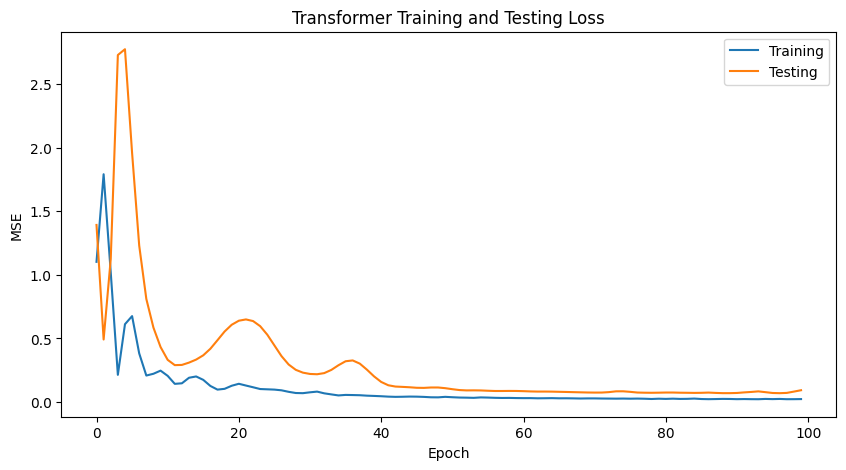

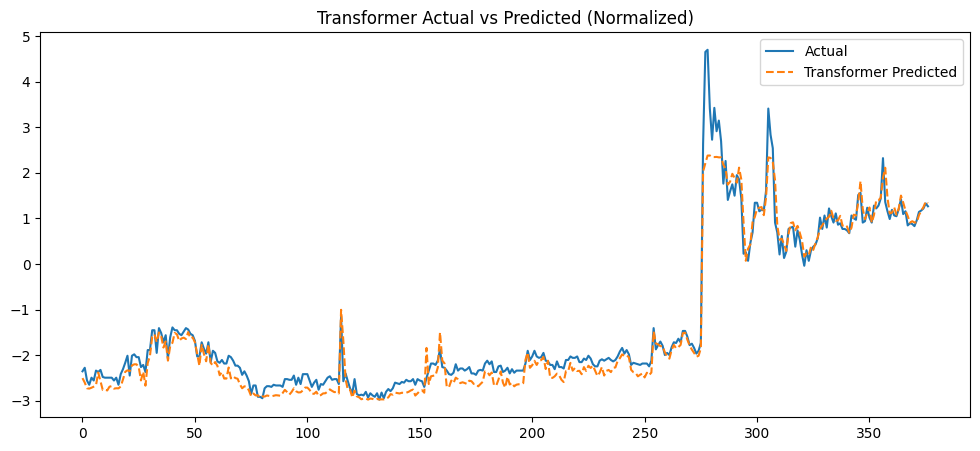

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

class TransformerModel(nn.Module):
    def __init__(
        self, input_size, hidden_size,
        output_size, num_layers,
        num_attention_heads
    ):
        super().__init__()

        self.embedding = nn.Linear(
            input_size, hidden_size
        )

        self.transformer = nn.Transformer(
            d_model=hidden_size,
            nhead=num_attention_heads,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers
        )

        self.fc_output = nn.Linear(
            hidden_size, output_size
        )

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(1, 0, 2)
        x = self.transformer(x, x)
        x = x.permute(1, 0, 2)

        return self.fc_output(
            x[:, -1, :]
        )


transformer_model = TransformerModel(
    input_size=3,
    hidden_size=64,
    output_size=1,
    num_layers=2,
    num_attention_heads=4
)

criterion_transformer = nn.MSELoss()

optimizer_transformer = optim.Adam(
    transformer_model.parameters(),
    lr=0.001
)

train_losses = []
test_losses = []

for epoch in range(100):

    transformer_model.train()
    optimizer_transformer.zero_grad()

    outputs = transformer_model(
        train_features.unsqueeze(1)
    )

    loss = criterion_transformer(
        outputs,
        train_target.unsqueeze(1)
    )

    loss.backward()
    optimizer_transformer.step()

    train_losses.append(loss.item())

    transformer_model.eval()

    with torch.no_grad():
        pred = transformer_model(
            test_features.unsqueeze(1)
        )

        test_loss = criterion_transformer(
            pred,
            test_target.unsqueeze(1)
        )

    test_losses.append(test_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Transformer Epoch {epoch+1}/100 | "
            f"Train: {loss.item():.5f} | "
            f"Test: {test_loss.item():.5f}"
        )

# Final test predictions
transformer_model.eval()

with torch.no_grad():
    test_predictions = transformer_model(
        test_features.unsqueeze(1)
    ).squeeze(1).cpu().numpy()

# Training and testing loss graph
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training")
plt.plot(test_losses, label="Testing")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Transformer Training and Testing Loss")
plt.legend()
plt.show()

# Actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(
    test_target.numpy(),
    label="Actual"
)
plt.plot(
    test_predictions,
    "--",
    label="Transformer Predicted"
)
plt.title("Transformer Actual vs Predicted (Normalized)")
plt.legend()
plt.show()


## GRU Model - Our Novel Approach


Epoch [10/100], Training Loss: 0.805511
Epoch [20/100], Training Loss: 0.549882
Epoch [30/100], Training Loss: 0.233670
Epoch [40/100], Training Loss: 0.028771
Epoch [50/100], Training Loss: 0.040257
Epoch [60/100], Training Loss: 0.022434
Epoch [70/100], Training Loss: 0.020346
Epoch [80/100], Training Loss: 0.019471
Epoch [90/100], Training Loss: 0.018381
Epoch [100/100], Training Loss: 0.018142

========== GRU TEST RESULTS ==========
MAE (Normalized):  0.2155
MSE (Normalized):  0.0948
RMSE (Normalized): 0.3080
R-squared:         0.9651

===== GRU ORIGINAL PRICE METRICS =====
MAE:  $0.1387
MSE:  0.0393
RMSE: $0.1982
MAPE: 5.9206%
R²:   0.9651


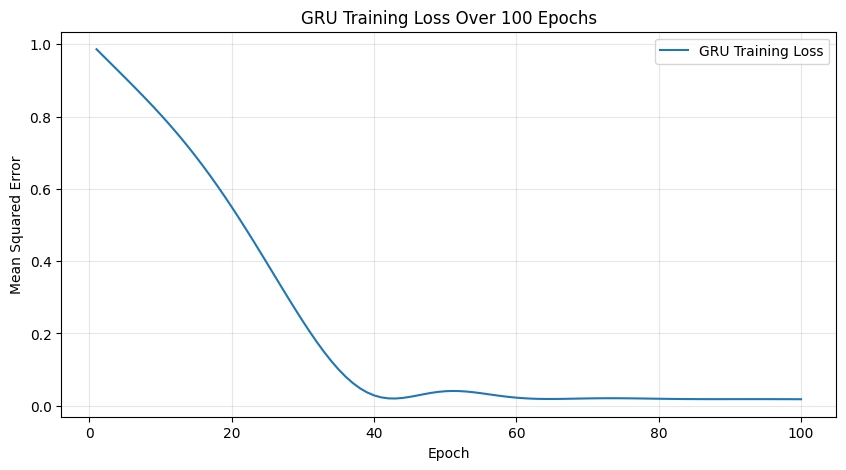

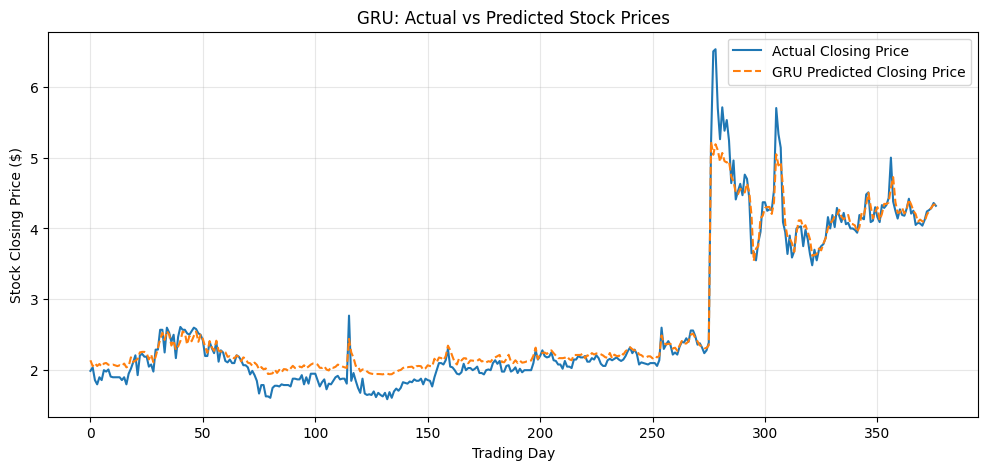


GRU training and evaluation complete!


In [14]:
# GRU MODEL - COMPARISON WITH LSTM AND TRANSFORMER


import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# DEFINE GRU MODEL

class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size,
                 num_layers, output_size):

        super(GRUModel, self).__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        gru_output, hidden = self.gru(x)
        return self.fc(gru_output[:, -1, :])


# DEFINE HYPERPARAMETERS

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Match LSTM and Transformer settings
input_size = 3
hidden_size = 64
num_layers = 2
output_size = 1

learning_rate = 0.001
num_epochs_gru = 100

# Create GRU model
model_gru = GRUModel(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=num_layers,
    output_size=output_size
)

# Define loss function and optimizer
criterion_gru = nn.MSELoss()

optimizer_gru = optim.Adam(
    model_gru.parameters(),
    lr=learning_rate
)


# TRAIN THE GRU MODEL

gru_train_losses = []

for epoch in range(num_epochs_gru):

    model_gru.train()
    optimizer_gru.zero_grad()

    # Forward pass
    outputs = model_gru(train_features.unsqueeze(1))

    # Calculate training loss
    loss = criterion_gru(
        outputs,
        train_target.unsqueeze(1)
    )

    # Backpropagation
    loss.backward()
    optimizer_gru.step()

    gru_train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs_gru}], "
            f"Training Loss: {loss.item():.6f}"
        )


# EVALUATE ON TEST DATASET

model_gru.eval()

with torch.no_grad():
    gru_predictions = model_gru(
        test_features.unsqueeze(1)
    )

gru_predictions = (
    gru_predictions.squeeze(1).cpu().numpy()
)

actual = test_target.cpu().numpy()


# CALCULATE NORMALIZED METRICS

gru_mae = mean_absolute_error(actual, gru_predictions)
gru_mse = mean_squared_error(actual, gru_predictions)
gru_rmse = np.sqrt(gru_mse)
gru_r2 = r2_score(actual, gru_predictions)

print("\n========== GRU TEST RESULTS ==========")

print(f"MAE (Normalized):  {gru_mae:.4f}")
print(f"MSE (Normalized):  {gru_mse:.4f}")
print(f"RMSE (Normalized): {gru_rmse:.4f}")
print(f"R-squared:         {gru_r2:.4f}")


# CONVERT BACK TO ORIGINAL STOCK PRICES

# Use normalization statistics from original preprocessing
close_index = columns_to_normalize.index('Close')

close_mean = mean[close_index].item()
close_std = std[close_index].item()

# Convert normalized values back to stock prices
actual_prices = actual * close_std + close_mean
predicted_prices = gru_predictions * close_std + close_mean

# Calculate original-price metrics
gru_mae_original = mean_absolute_error(
    actual_prices, predicted_prices
)

gru_mse_original = mean_squared_error(
    actual_prices, predicted_prices
)

gru_rmse_original = np.sqrt(gru_mse_original)

# Calculate MAPE using original stock prices
gru_mape = np.mean(
    np.abs(
        (actual_prices - predicted_prices) /
        np.maximum(np.abs(actual_prices), 1e-8)
    )
) * 100

print("\n===== GRU ORIGINAL PRICE METRICS =====")

print(f"MAE:  ${gru_mae_original:.4f}")
print(f"MSE:  {gru_mse_original:.4f}")
print(f"RMSE: ${gru_rmse_original:.4f}")
print(f"MAPE: {gru_mape:.4f}%")
print(f"R²:   {gru_r2:.4f}")


# VISUALIZE TRAINING LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs_gru + 1),
    gru_train_losses,
    label="GRU Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("GRU Training Loss Over 100 Epochs")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# VISUALIZE ACTUAL VS PREDICTED STOCK PRICES

plt.figure(figsize=(12, 5))

plt.plot(
    actual_prices,
    label="Actual Closing Price"
)

plt.plot(
    predicted_prices,
    label="GRU Predicted Closing Price",
    linestyle="dashed"
)

plt.xlabel("Trading Day")
plt.ylabel("Stock Closing Price ($)")
plt.title("GRU: Actual vs Predicted Stock Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\nGRU training and evaluation complete!")


In [15]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Retrieve training-only normalization statistics
close_index = columns_to_normalize.index("Close")
close_mean = mean[close_index].item()
close_std = std[close_index].item()

def to_original_prices(values):
    values = np.asarray(values).reshape(-1)
    return values * close_std + close_mean

# Verify the test tensors match the shared split
actual = to_original_prices(
    test_target.detach().cpu().numpy()
)

assert len(actual) == len(test_raw)
assert np.allclose(
    actual,
    test_raw["Close"].to_numpy(),
    atol=1e-4
), "Test tensors do not match the shared AAME split."

def calculate_metrics(predictions):
    predicted = to_original_prices(predictions)

    if len(predicted) != len(actual):
        raise ValueError(
            "Predictions do not match test observations"
        )

    mse = mean_squared_error(
        actual, predicted
    )

    mape = np.mean(
        np.abs(
            (actual - predicted) /
            np.maximum(np.abs(actual), 1e-8)
        )
    ) * 100

    return {
        "MAE ($)": mean_absolute_error(
            actual, predicted
        ),
        "MSE ($²)": mse,
        "RMSE ($)": np.sqrt(mse),
        "MAPE (%)": mape,
        "R²": r2_score(actual, predicted)
    }

comparison = pd.DataFrame({
    "LSTM": calculate_metrics(
        test_predictions_lstm
    ),
    "Transformer": calculate_metrics(
        test_predictions
    ),
    "GRU": calculate_metrics(
        gru_predictions
    )
}).T

print("\nMODEL PERFORMANCE COMPARISON")
print(comparison.round(4))



MODEL PERFORMANCE COMPARISON
             MAE ($)  MSE ($²)  RMSE ($)  MAPE (%)      R²
LSTM          0.1927    0.0674    0.2595    8.4772  0.9402
Transformer   0.1370    0.0385    0.1961    5.4966  0.9659
GRU           0.1387    0.0393    0.1982    5.9206  0.9651


LSTM performed best overall, with the lowest MAE, MSE, and RMSE.

GRU performed second best in RMSE, outperforming Transformer by about 1.7%.

Transformer performed slightly better than GRU in MAE, though the difference was small.